# Option C — Environmental Sound Analysis: Clock Tick

**Question:** How do 512-sample and 2048-sample windows change the time–frequency representation of the same clock-tick recording when sampling rate and hop size are fixed?

**Supplied recording:** `data/1-21934-A-38.wav` (ESC-50 subset, label `clock_tick`), originally 44,100 Hz, 5 seconds. This notebook resamples to **16,000 Hz** and uses a **160-sample hop** for both spectrograms. The original sound is attributed in `licenses/ESC50_LICENSE.txt`.

This notebook is an individual **Option C** analysis. It does not use a sound classifier, change the input recording, or compare noise reduction models.

In [1]:
from pathlib import Path
import math
import numpy as np
import soundfile as sf
import matplotlib.pyplot as plt
from scipy.signal import resample_poly, stft
from IPython.display import Audio, display, Image

ROOT = Path.cwd()
AUDIO_FILE = ROOT / 'data' / '1-21934-A-38.wav'
OUT = ROOT / 'results'
OUT.mkdir(exist_ok=True)
FS = 16_000
HOP = 160
WINDOW_SIZES = (512, 2048)

assert AUDIO_FILE.is_file(), f'Missing supplied audio: {AUDIO_FILE}'
recording, original_fs = sf.read(AUDIO_FILE, dtype='float64', always_2d=True)
mono = recording.mean(axis=1)
g = math.gcd(original_fs, FS)
y = resample_poly(mono, FS // g, original_fs // g)
t = np.arange(len(y)) / FS

def export_figure(filename):
    plt.savefig(OUT / filename, dpi=170, bbox_inches='tight')
    plt.close()
    display(Image(filename=str(OUT / filename)))

print('Audio:', AUDIO_FILE.name)
print('Original sample rate:', original_fs, 'Hz')
print('Analysis sample rate:', FS, 'Hz')
print('Duration:', round(len(y)/FS, 3), 's')
print('Number of analysis samples:', len(y))

Audio: 1-21934-A-38.wav
Original sample rate: 44100 Hz
Analysis sample rate: 16000 Hz
Duration: 5.0 s
Number of analysis samples: 80000


## 1. Listen to the supplied audio

Play the recording below. **Listening note to complete after playback:** describe what you hear in one sentence (for example, whether clicks are evenly spaced and whether background sounds are present). This note must come from your own listening, not from the filename alone.

In [2]:
display(Audio(y, rate=FS, normalize=False))

## 2. Waveform

A waveform shows where rapid, short-amplitude changes occur. The marked interval **2.49–2.58 s** is selected for closer inspection. It contains a conspicuous transient in this recording; it is not a separately annotated ground-truth event.

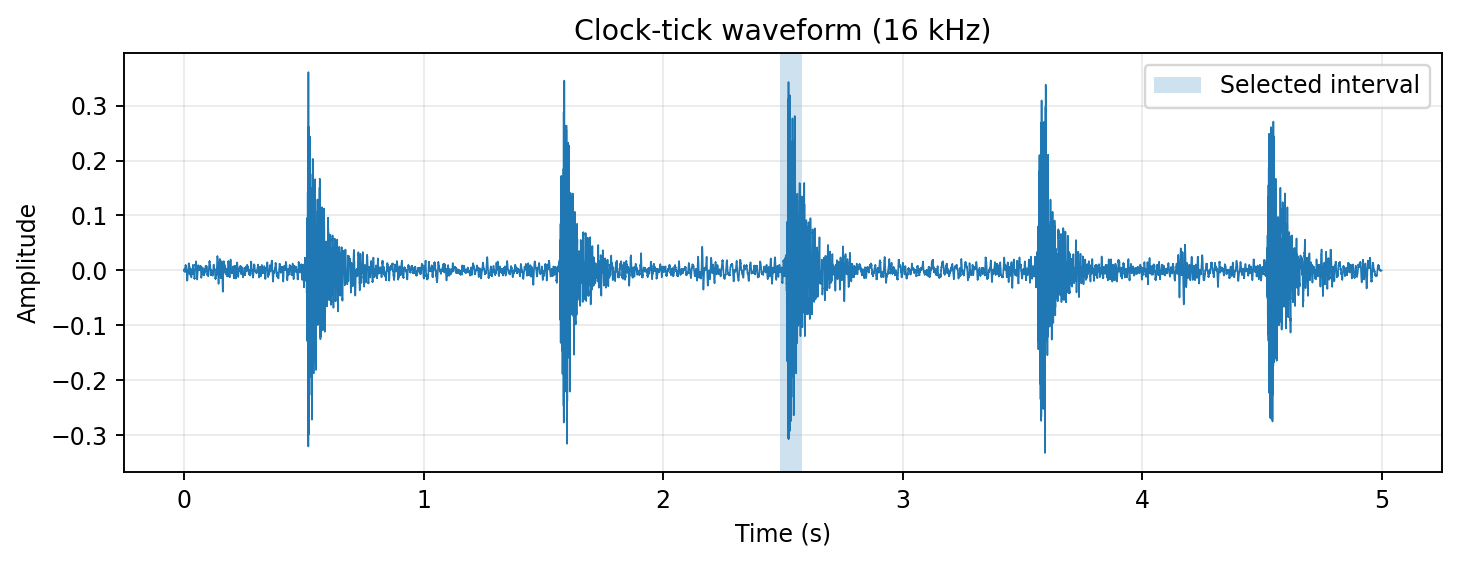

In [3]:
FOCUS_START, FOCUS_END = 2.49, 2.58
fig, ax = plt.subplots(figsize=(10, 3.2))
ax.plot(t, y, linewidth=0.7)
ax.axvspan(FOCUS_START, FOCUS_END, alpha=0.22, label='Selected interval')
ax.set(xlabel='Time (s)', ylabel='Amplitude', title='Clock-tick waveform (16 kHz)')
ax.legend(loc='upper right')
ax.grid(alpha=0.25)
export_figure('01_waveform.png')

## 3. Frequency spectrum

The magnitude spectrum shows energy across frequency but cannot show *when* events occurred. A Hann window is applied before the FFT to reduce spectral leakage. The highlighted **1–3 kHz** band is a relevant region around the selected tick transient; it is not an exclusive description of all sound energy.

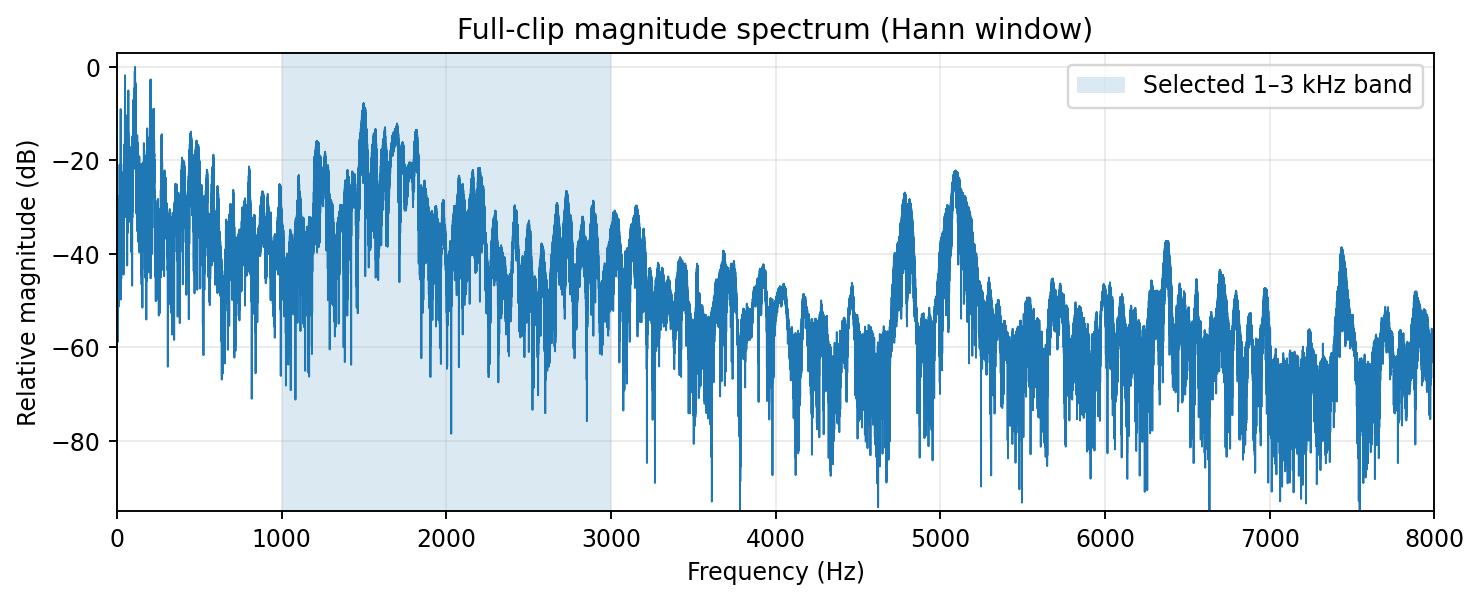

In [4]:
window = np.hanning(len(y))
freq = np.fft.rfftfreq(len(y), d=1/FS)
spec = np.abs(np.fft.rfft(y * window))
spec_db = 20 * np.log10(np.maximum(spec / max(spec.max(), 1e-12), 1e-8))
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(freq, spec_db, linewidth=0.8)
ax.axvspan(1000, 3000, alpha=0.16, label='Selected 1–3 kHz band')
ax.set(xlim=(0, 8000), ylim=(-95, 3), xlabel='Frequency (Hz)', ylabel='Relative magnitude (dB)', title='Full-clip magnitude spectrum (Hann window)')
ax.grid(alpha=0.25)
ax.legend(loc='upper right')
export_figure('02_frequency_spectrum.png')

## 4. Spectrograms: 512 versus 2048 samples

The two STFTs below use the **same 16 kHz recording**, **Hann windows**, and **160-sample hop** (10 ms). Both have no additional zero-padding. The window sizes produce different FFT-bin spacings:

- 512 samples: `16000/512 = 31.25 Hz`, window duration `512/16000 = 0.032 s` (32 ms).
- 2048 samples: `16000/2048 = 7.8125 Hz`, window duration `2048/16000 = 0.128 s` (128 ms).

The larger window gives finer frequency-bin spacing but spreads a short transient over a longer temporal window. Identical hop size means the spectrogram columns are similarly spaced in time, **not** that the underlying time resolution is identical.

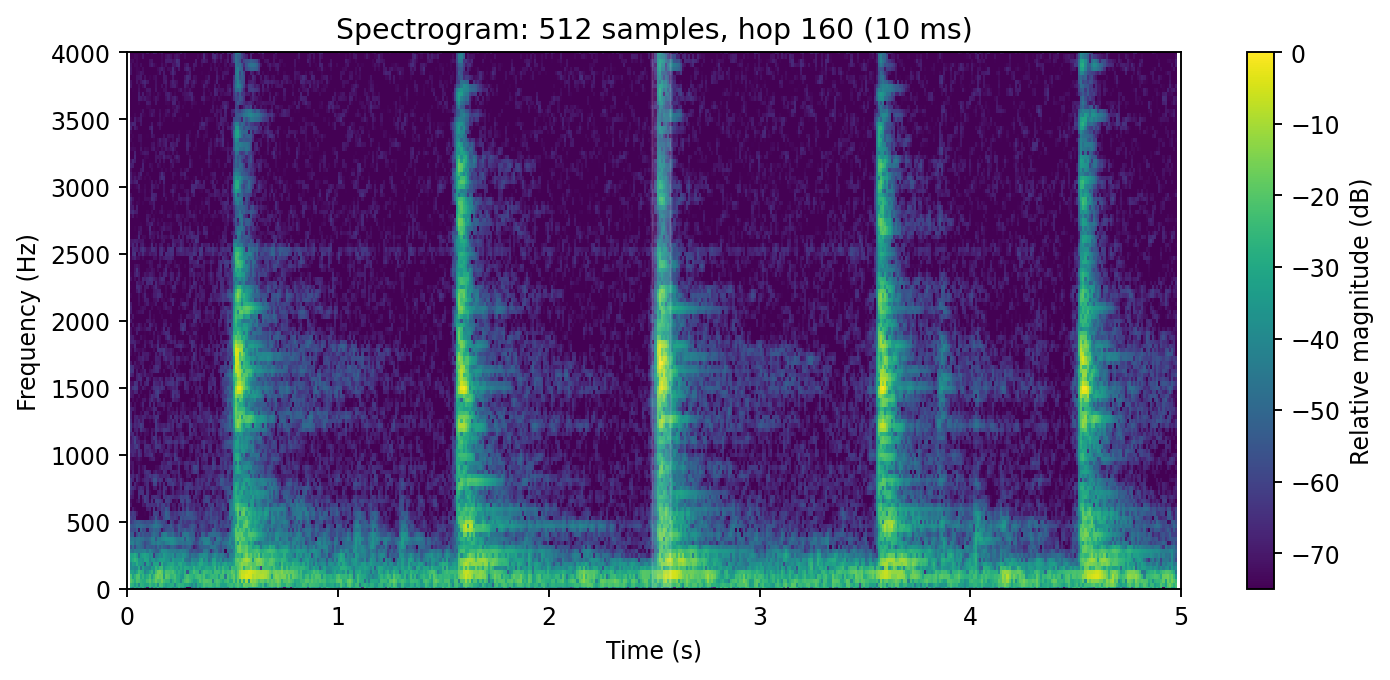

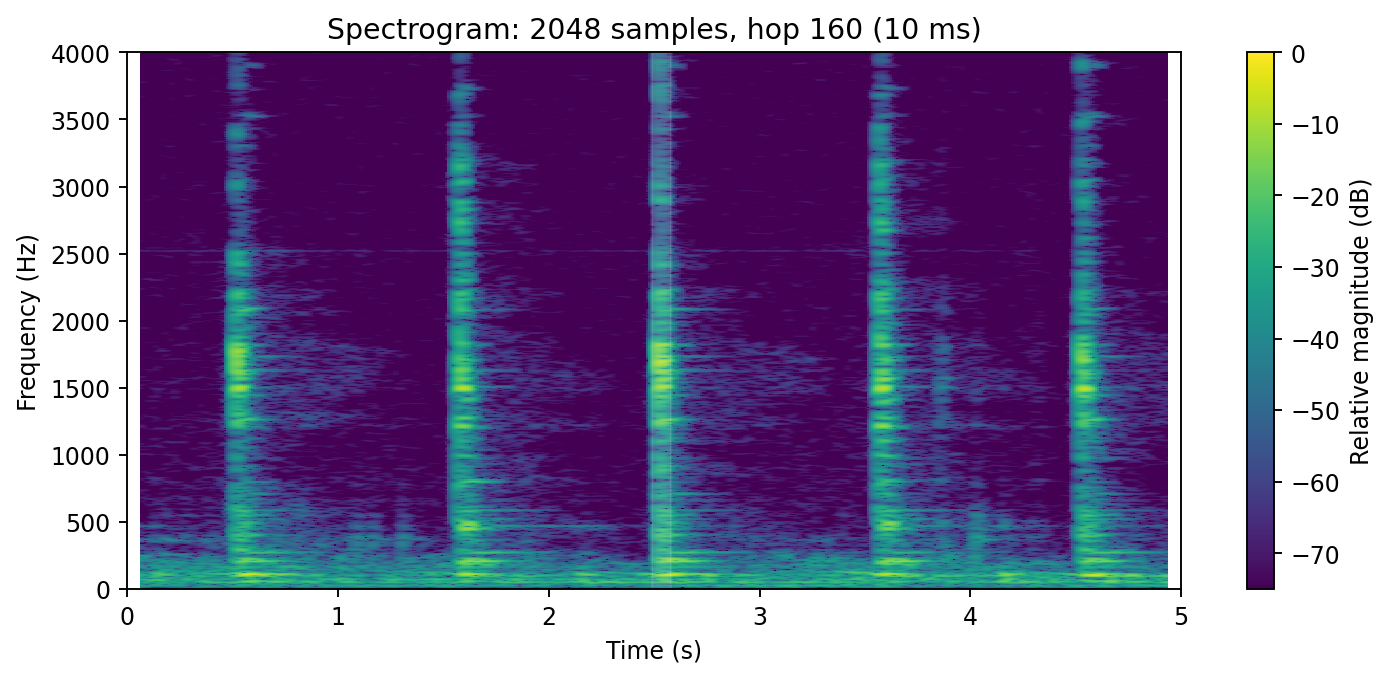

In [5]:
stfts = {}
for nperseg in WINDOW_SIZES:
    f_stft, t_stft, Z = stft(
        y, fs=FS, window='hann', nperseg=nperseg,
        noverlap=nperseg-HOP, nfft=nperseg,
        boundary=None, padded=False, scaling='spectrum'
    )
    stfts[nperseg] = (f_stft, t_stft, Z)

# Common decibel reference makes the two displays directly comparable.
shared_max = max(np.abs(item[2]).max() for item in stfts.values())
DB_FLOOR = -75
for nperseg in WINDOW_SIZES:
    f_stft, t_stft, Z = stfts[nperseg]
    db = 20 * np.log10(np.maximum(np.abs(Z) / shared_max, 1e-9))
    fig, ax = plt.subplots(figsize=(10, 4.1))
    mesh = ax.pcolormesh(t_stft, f_stft, db, shading='auto', cmap='viridis', vmin=DB_FLOOR, vmax=0)
    ax.set(xlabel='Time (s)', ylabel='Frequency (Hz)', ylim=(0, 4000), xlim=(0, len(y)/FS),
           title=f'Spectrogram: {nperseg} samples, hop {HOP} (10 ms)')
    ax.axvspan(FOCUS_START, FOCUS_END, color='white', alpha=0.10)
    fig.colorbar(mesh, ax=ax, label='Relative magnitude (dB)')
    export_figure(f'03_spectrogram_{nperseg}.png' if nperseg==512 else f'04_spectrogram_{nperseg}.png')

## 5. Specific interval and frequency region

**Chosen event interval:** 2.49–2.58 seconds. **Relevant band:** approximately 1–3 kHz. The 512-sample spectrogram localizes the brief tick more closely in time; the 2048-sample spectrogram provides more closely spaced frequency bins, but the transient extends across a wider time region. The recording also has lower-frequency energy, so the selected band is not the entire spectrum.

The following calculation reports the strongest *local* spectral peak within the selected band, and RMS amplitude in the interval. These measurements describe this one clip, not clock ticks generally.

In [6]:
start = int(round(FOCUS_START * FS))
end = int(round(FOCUS_END * FS))
clip = y[start:end]
clip_freq = np.fft.rfftfreq(len(clip), d=1/FS)
clip_mag = np.abs(np.fft.rfft(clip * np.hanning(len(clip))))
valid = (clip_freq >= 1000) & (clip_freq <= 3000)
peak_freq = clip_freq[valid][np.argmax(clip_mag[valid])]
interval_rms = float(np.sqrt(np.mean(clip ** 2)))
print(f'Selected interval: {FOCUS_START:.2f}–{FOCUS_END:.2f} s')
print(f'Frequency band: 1000–3000 Hz')
print(f'Strongest local spectral peak within band: {peak_freq:.1f} Hz')
print(f'RMS in selected interval: {interval_rms:.5f}')
print(f'512 bins: {FS/512:.4f} Hz, window {512/FS*1000:.1f} ms')
print(f'2048 bins: {FS/2048:.4f} Hz, window {2048/FS*1000:.1f} ms')
print(f'Common hop: {HOP/FS*1000:.1f} ms')

Selected interval: 2.49–2.58 s
Frequency band: 1000–3000 Hz
Strongest local spectral peak within band: 1688.9 Hz
RMS in selected interval: 0.08685
512 bins: 31.2500 Hz, window 32.0 ms
2048 bins: 7.8125 Hz, window 128.0 ms
Common hop: 10.0 ms


## 6. Conclusion and limitation

**Conclusion.** The shorter 512-sample window shows the transient timing more sharply, while the 2048-sample window gives finer frequency sampling. Both use the same 10-ms hop, so the visual difference arises from the window length rather than a different input or hop size.

**Limitation.** A fixed-window STFT trades temporal and frequency resolution: no single window size captures both short click timing and fine frequency detail equally well. In addition, this is **one** supplied recording, so the findings cannot be generalized to all clock or environmental sounds.

**Listening verification:** After playing the audio in Section 1, replace this line with a short personal observation. No listening observation has been invented.